# QAI Control — Preparação de Dados e Formulação do Problema Preditivo



In [1]:
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd


try:
    from google.colab import files

    print("Selecione o arquivo .zip da base:")
    uploaded = files.upload()

    zip_names = [name for name in uploaded.keys() if name.lower().endswith(".zip")]

    if not zip_names:
        raise FileNotFoundError("Nenhum arquivo .zip foi enviado.")

    ZIP_PATH = Path(zip_names[0])

except ImportError:
    # Execução fora do Colab
    candidatos = [
        Path("synthetic_ai_usage_dataset (1) (1).zip"),
        Path("/mnt/data/synthetic_ai_usage_dataset (1) (1).zip"),
    ]
    ZIP_PATH = next((p for p in candidatos if p.exists()), None)

    if ZIP_PATH is None:
        raise FileNotFoundError(
            "Arquivo .zip não encontrado. Coloque-o na mesma pasta do notebook."
        )

print(f"Arquivo utilizado: {ZIP_PATH}")

EXTRACT_DIR = Path("qai_dataset")
EXTRACT_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

csv_files = list(EXTRACT_DIR.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("Nenhum arquivo CSV foi encontrado dentro do .zip.")

CSV_DIR = csv_files[0].parent

dfs = {
    arquivo.name: pd.read_csv(arquivo, low_memory=False)
    for arquivo in sorted(CSV_DIR.glob("*.csv"))
}

print(f"\n{len(dfs)} tabelas carregadas com sucesso.")
print("Pasta dos CSVs:", CSV_DIR)
sorted(dfs.keys())


Selecione o arquivo .zip da base:


Saving synthetic_ai_usage_dataset.zip to synthetic_ai_usage_dataset.zip
Arquivo utilizado: synthetic_ai_usage_dataset.zip

17 tabelas carregadas com sucesso.
Pasta dos CSVs: qai_dataset/synthetic_ai_usage_dataset/csv


['ai_billing.csv',
 'ai_budgets.csv',
 'ai_licenses.csv',
 'ai_models.csv',
 'ai_tools.csv',
 'ai_usage_logs.csv',
 'approved_ai_tools.csv',
 'builds.csv',
 'companies.csv',
 'departments.csv',
 'deployments.csv',
 'employees.csv',
 'issues.csv',
 'projects.csv',
 'pull_requests.csv',
 'security_events.csv',
 'training_records.csv']

## 1. Diagnóstico inicial da base

In [2]:
resumo_tabelas = []

for nome, df in sorted(dfs.items()):
    resumo_tabelas.append({
        "tabela": nome,
        "linhas": df.shape[0],
        "colunas": df.shape[1],
        "duplicatas": int(df.duplicated().sum()),
        "celulas_nulas": int(df.isna().sum().sum())
    })

resumo_tabelas = pd.DataFrame(resumo_tabelas)
display(resumo_tabelas)


,tabela,linhas,colunas,duplicatas,celulas_nulas
0,ai_billing.csv,7025,10,0,5684
1,ai_budgets.csv,2254,5,0,0
2,ai_licenses.csv,5605,7,0,1574
3,ai_models.csv,25,6,0,10
4,ai_tools.csv,15,5,0,0
5,ai_usage_logs.csv,269515,15,0,219221
6,approved_ai_tools.csv,105,5,0,48
7,builds.csv,12414,7,0,0
8,companies.csv,18,5,0,0
9,departments.csv,161,3,0,0


In [3]:
diagnostico = []

for nome, df in sorted(dfs.items()):
    for coluna in df.columns:
        diagnostico.append({
            "tabela": nome,
            "coluna": coluna,
            "tipo": str(df[coluna].dtype),
            "nulos_qtd": int(df[coluna].isna().sum()),
            "nulos_pct": round(df[coluna].isna().mean() * 100, 2),
            "cardinalidade": int(df[coluna].nunique(dropna=True))
        })

diagnostico = pd.DataFrame(diagnostico)

display(
    diagnostico
    .sort_values(["nulos_pct", "cardinalidade"], ascending=[False, False])
    .head(30)
)


,tabela,coluna,tipo,nulos_qtd,nulos_pct,cardinalidade
46,ai_usage_logs.csv,project_id,object,206909,76.77,18
5,ai_billing.csv,model_id,object,5258,74.85,10
52,approved_ai_tools.csv,allowed_departments,object,48,45.71,14
120,training_records.csv,completion_date,object,678,42.45,371
122,training_records.csv,score,float64,678,42.45,46
87,issues.csv,closed_at,object,1403,40.61,1966
20,ai_licenses.csv,expiration_date,object,1574,28.08,460
99,pull_requests.csv,merged_at,object,1227,23.95,3897
26,ai_models.csv,input_price_usd_per_1k_tokens,float64,5,20.00,8
27,ai_models.csv,output_price_usd_per_1k_tokens,float64,5,20.00,7


### Decisão

O diagnóstico é feito antes de qualquer transformação. A intenção é separar problemas de **estrutura**, **tipo**, **conteúdo** e **semântica**.

Os identificadores permanecem na base para relacionamento e rastreabilidade, mas não serão tratados como variáveis categóricas do modelo.


## 2. Análise dos valores ausentes

In [4]:
usage = dfs["ai_usage_logs.csv"].copy()

latency_por_status = (
    usage.groupby("request_status")["latency_ms"]
    .apply(lambda s: round(s.isna().mean() * 100, 2))
    .rename("latency_ms_nulo_pct")
)

display(latency_por_status)


,latency_ms_nulo_pct
request_status,
error,40.56
rate_limited,39.01
success,0.00
timeout,39.48


### `latency_ms`: ausência como sinal

A ausência de `latency_ms` se concentra em situações de falha (`error`, `timeout` e `rate_limited`). Por isso, ela não será apagada por uma imputação automática.

A decisão é:

- preservar o valor ausente;
- criar um indicador `latency_missing`;
- nas agregações mensais, calcular a latência média somente com valores observados e manter separadamente a taxa de ausência.

Assim, o modelo poderá receber a informação de que a latência não foi registrada sem inventar um valor de latência.


In [5]:
print("project_id ausente em ai_usage_logs:")
print(round(dfs["ai_usage_logs.csv"]["project_id"].isna().mean() * 100, 2), "%")

print("\nmodel_id ausente em ai_billing:")
print(round(dfs["ai_billing.csv"]["model_id"].isna().mean() * 100, 2), "%")

print("\nexpiration_date ausente em ai_licenses:")
print(round(dfs["ai_licenses.csv"]["expiration_date"].isna().mean() * 100, 2), "%")

print("\ncompletion_date ausente em training_records:")
print(round(dfs["training_records.csv"]["completion_date"].isna().mean() * 100, 2), "%")


project_id ausente em ai_usage_logs:
76.77 %

model_id ausente em ai_billing:
74.85 %

expiration_date ausente em ai_licenses:
28.08 %

completion_date ausente em training_records:
42.45 %


### NaN estrutural

Os campos acima não devem receber automaticamente média, mediana ou moda.

- `project_id`: nem todo uso de IA está ligado a projeto;
- `model_id` em faturamento: cobrança por licença/assento pode não ter um modelo associado;
- `expiration_date`: pode não existir para determinados acordos;
- `completion_date` e `score`: não existem quando o treinamento não foi concluído.

Nesses casos, o vazio pode significar **“não se aplica”**, e não necessariamente “dado perdido”.


## 3. Correção de tipos

In [6]:
clean = {nome: df.copy() for nome, df in dfs.items()}

colunas_data = {
    "ai_usage_logs.csv": ["timestamp"],
    "employees.csv": ["hire_date"],
    "ai_licenses.csv": ["assigned_date", "expiration_date"],
    "training_records.csv": ["enrollment_date", "completion_date"],
    "security_events.csv": ["timestamp"],
    "projects.csv": ["start_date"],
    "pull_requests.csv": ["created_at", "merged_at"],
    "issues.csv": ["created_at", "closed_at"],
    "builds.csv": ["timestamp"],
    "deployments.csv": ["timestamp"],
    "approved_ai_tools.csv": ["approval_date"],
}

for tabela, colunas in colunas_data.items():
    for coluna in colunas:
        clean[tabela][coluna] = pd.to_datetime(
            clean[tabela][coluna],
            errors="coerce"
        )

# billing_month representa mês, e não uma data diária.
clean["ai_billing.csv"]["billing_month"] = (
    clean["ai_billing.csv"]["billing_month"]
    .astype(str)
    .str[:7]
)

print(clean["ai_usage_logs.csv"]["timestamp"].dtype)
print(clean["employees.csv"]["hire_date"].dtype)
print(clean["ai_billing.csv"]["billing_month"].head())


datetime64[ns]
datetime64[ns]
0    2025-06
1    2025-06
2    2025-06
3    2025-06
4    2025-06
Name: billing_month, dtype: object


As colunas temporais são convertidas antes da análise de conteúdo. `billing_month` permanece no formato `AAAA-MM`, porque a própria base informa apenas o mês da cobrança.


## 4. Conversão USD → BRL com série oficial do Banco Central

O feedback apontou corretamente que as taxas usadas anteriormente alternavam entre dois valores praticamente constantes e não possuíam fonte documentada.

Nesta versão, elas são substituídas por dados oficiais do **Banco Central do Brasil (BCB)**.

**Fonte:** Banco Central do Brasil — **Sistema PTAX**, utilizando as cotações oficiais do dólar americano para venda disponibilizadas pela API PTAX.

Como `ai_billing` possui apenas o mês da cobrança, e não o dia exato da fatura, utilizamos a **média das cotações diárias de venda de cada mês**. Essa é uma aproximação explícita e auditável. Caso a data exata da cobrança esteja disponível futuramente, a conversão poderá utilizar a cotação correspondente àquela data.


In [7]:
import requests
import pandas as pd
import time

billing = clean["ai_billing.csv"].copy()

# Intervalo necessário de acordo com a base
mes_min = pd.Period(billing["billing_month"].min(), freq="M")
mes_max = pd.Period(billing["billing_month"].max(), freq="M")

# A API PTAX usa MM-DD-AAAA
data_inicial = mes_min.start_time.strftime("%m-%d-%Y")
data_final = mes_max.end_time.strftime("%m-%d-%Y")

url_ptax = (
    "https://olinda.bcb.gov.br/olinda/servico/PTAX/versao/v1/"
    "odata/CotacaoDolarPeriodo"
    f"(dataInicial=@dataInicial,dataFinalCotacao=@dataFinalCotacao)"
    f"?@dataInicial='{data_inicial}'"
    f"&@dataFinalCotacao='{data_final}'"
    "&$format=json"
)

# Faz algumas tentativas caso a API demore
resposta = None

for tentativa in range(3):
    try:
        resposta = requests.get(url_ptax, timeout=90)
        resposta.raise_for_status()
        break

    except requests.exceptions.RequestException as erro:
        print(f"Tentativa {tentativa + 1} falhou: {erro}")

        if tentativa < 2:
            print("Tentando novamente...")
            time.sleep(5)
        else:
            raise

dados = resposta.json()["value"]

ptax_diaria = pd.DataFrame(dados)

if ptax_diaria.empty:
    raise ValueError(
        "A API PTAX do Banco Central não retornou cotações para o período."
    )

display(ptax_diaria.head())

# Converte a data/hora retornada pela PTAX
ptax_diaria["dataHoraCotacao"] = pd.to_datetime(
    ptax_diaria["dataHoraCotacao"],
    errors="coerce"
)

# Cria o mês de referência
ptax_diaria["billing_month"] = (
    ptax_diaria["dataHoraCotacao"]
    .dt.to_period("M")
    .astype(str)
)

# Como pode haver mais de uma cotação no mesmo dia,
# primeiro calculamos a média diária da cotação de venda
ptax_por_dia = (
    ptax_diaria
    .assign(data=ptax_diaria["dataHoraCotacao"].dt.date)
    .groupby(["data", "billing_month"], as_index=False)["cotacaoVenda"]
    .mean()
)

# Depois calculamos a média mensal
ptax_mensal = (
    ptax_por_dia
    .groupby("billing_month", as_index=False)["cotacaoVenda"]
    .mean()
    .rename(columns={"cotacaoVenda": "fx_rate_to_brl"})
)

display(ptax_mensal)

,cotacaoCompra,cotacaoVenda,dataHoraCotacao
0,5.6931,5.6937,2025-06-02 13:09:05.107
1,5.6688,5.6694,2025-06-03 13:07:29.518
2,5.6326,5.6332,2025-06-04 13:11:29.327
3,5.5963,5.5969,2025-06-05 13:07:30.991
4,5.5941,5.5947,2025-06-06 13:08:48.677


,billing_month,fx_rate_to_brl
0,2025-06,5.547055
1,2025-07,5.528491
2,2025-08,5.446924
3,2025-09,5.367409
4,2025-10,5.385526
5,2025-11,5.340853
6,2025-12,5.453091
7,2026-01,5.338024
8,2026-02,5.200617
9,2026-03,5.231586


In [8]:
billing["currency_original"] = billing["currency"]
billing["total_cost_original"] = billing["total_cost"]

billing = billing.merge(
    ptax_mensal,
    on="billing_month",
    how="left"
)

# Para valores que já estão em BRL, a taxa é 1.
billing.loc[billing["currency"].eq("BRL"), "fx_rate_to_brl"] = 1.0

# Verificação: nenhum lançamento em USD pode ficar sem cotação.
sem_cotacao = billing.loc[
    billing["currency"].eq("USD") & billing["fx_rate_to_brl"].isna()
]

if len(sem_cotacao) > 0:
    raise ValueError(
        f"Há {len(sem_cotacao)} lançamentos em USD sem taxa de câmbio."
    )

billing["total_cost_brl"] = (
    billing["total_cost_original"] * billing["fx_rate_to_brl"]
).round(2)

billing["currency_standard"] = "BRL"

clean["ai_billing.csv"] = billing

display(
    billing[
        [
            "billing_month",
            "total_cost_original",
            "currency_original",
            "fx_rate_to_brl",
            "total_cost_brl",
            "currency_standard"
        ]
    ].head(10)
)


,billing_month,total_cost_original,currency_original,fx_rate_to_brl,total_cost_brl,currency_standard
0,2025-06,1.87,USD,5.547055,10.37,BRL
1,2025-06,0.74,USD,5.547055,4.10,BRL
2,2025-06,2.73,USD,5.547055,15.14,BRL
3,2025-06,11.46,USD,5.547055,63.57,BRL
4,2025-06,0.33,USD,5.547055,1.83,BRL
5,2025-06,1.22,USD,5.547055,6.77,BRL
6,2025-06,0.78,USD,5.547055,4.33,BRL
7,2025-06,0.63,USD,5.547055,3.49,BRL
8,2025-06,0.11,USD,5.547055,0.61,BRL
9,2025-06,1.22,USD,5.547055,6.77,BRL


### Por que preservar os campos originais?

`total_cost_original` e `currency_original` permanecem intactos. A taxa aplicada também é armazenada em `fx_rate_to_brl`.

Isso torna a conversão:

- auditável;
- reversível;
- reproduzível;
- atualizável sem perda do dado bruto.


## 5. Formulação do problema preditivo

O feedback do Deliverable 1 pede quatro respostas explícitas.

### 5.1 O que será previsto?

Será previsto o **Risk Score de Dependência de IA do colaborador no mês seguinte**, em escala contínua de **0 a 100**.

O score representa uma **proxy operacional de risco**, porque a base não contém um rótulo observado de dependência.

### 5.2 Qual é a unidade de análise?

**Colaborador × mês.**

Cada linha da base analítica representa o comportamento de um colaborador durante um mês.

### 5.3 Qual é a tarefa?

**Regressão.**

O alvo é contínuo, variando de 0 a 100.

### 5.4 Qual é a métrica principal?

**MAE — Mean Absolute Error (Erro Absoluto Médio).**

O MAE é a métrica principal porque está na mesma unidade do score. Assim, se o MAE for 6, por exemplo, significa que a previsão erra em média cerca de 6 pontos em uma escala de 0 a 100.

Isso corresponde diretamente à decisão do gestor: o score será usado para **priorizar colaboradores com maior risco para análise, acompanhamento e ações de governança**. Uma métrica expressa em pontos do próprio score é simples de interpretar nesse contexto.

`R²` pode ser apresentado como métrica complementar, mas não substitui o MAE como métrica principal.


## 6. Construção da unidade colaborador × mês

In [9]:
usage = clean["ai_usage_logs.csv"].copy()

usage["year_month"] = usage["timestamp"].dt.to_period("M").astype(str)
usage["hour"] = usage["timestamp"].dt.hour
usage["day_of_week"] = usage["timestamp"].dt.dayofweek

usage["latency_missing"] = usage["latency_ms"].isna().astype(int)
usage["is_failure"] = (usage["request_status"] != "success").astype(int)
usage["total_tokens"] = usage["input_tokens"] + usage["output_tokens"]

# Indicadores temporais observáveis no próprio mês.
usage["is_weekend"] = (usage["day_of_week"] >= 5).astype(int)
usage["is_off_hours"] = (
    (usage["hour"] < 8) | (usage["hour"] >= 19)
).astype(int)

usage.head()


,usage_id,timestamp,employee_id,company_id,department_id,ai_tool_id,model_id,application,request_count,input_tokens,...,project_id,cost_center,year_month,hour,day_of_week,latency_missing,is_failure,total_tokens,is_weekend,is_off_hours
0,U0000001,2026-03-27 21:26:54,C01-E0001,C01,C01-D02,T07,M10,Extensao VSCode,18,1526,...,C01-P01,CC-C01-D02,2026-03,21,4,0,0,4959,0,1
1,U0000002,2026-04-08 11:09:07,C01-E0001,C01,C01-D02,T07,M10,Extensao VSCode,32,3610,...,C01-P03,CC-C01-D02,2026-04,11,2,0,0,6210,0,0
2,U0000003,2026-04-07 12:12:04,C01-E0001,C01,C01-D02,T07,M10,Extensao VSCode,18,1226,...,C01-P01,CC-C01-D02,2026-04,12,1,0,0,4740,0,0
3,U0000004,2026-04-07 21:34:24,C01-E0001,C01,C01-D02,T02,M04,Chat Web,1,235,...,NaN,CC-C01-D02,2026-04,21,1,0,0,982,0,1
4,U0000005,2026-05-26 14:07:13,C01-E0001,C01,C01-D02,T07,M10,Extensao VSCode,33,3821,...,C01-P03,CC-C01-D02,2026-05,14,1,0,0,5231,0,0


In [10]:
# Concentração por ferramenta (HHI) dentro de cada colaborador/mês.
tool_count = (
    usage
    .groupby(["employee_id", "year_month", "ai_tool_id"])
    .size()
    .rename("n")
    .reset_index()
)

tool_count["total_mes"] = (
    tool_count
    .groupby(["employee_id", "year_month"])["n"]
    .transform("sum")
)

tool_count["share2"] = (
    tool_count["n"] / tool_count["total_mes"]
) ** 2

tool_hhi = (
    tool_count
    .groupby(["employee_id", "year_month"], as_index=False)["share2"]
    .sum()
    .rename(columns={"share2": "tool_hhi"})
)

mensal = (
    usage
    .groupby(["employee_id", "year_month"], as_index=False)
    .agg(
        usage_events=("usage_id", "count"),
        requests_total=("request_count", "sum"),
        total_tokens=("total_tokens", "sum"),
        active_days=("timestamp", lambda s: s.dt.date.nunique()),
        distinct_tools=("ai_tool_id", "nunique"),
        distinct_applications=("application", "nunique"),
        latency_ms_mean=("latency_ms", "mean"),
        latency_missing_rate=("latency_missing", "mean"),
        failure_rate=("is_failure", "mean"),
        weekend_usage_rate=("is_weekend", "mean"),
        off_hours_usage_rate=("is_off_hours", "mean"),
    )
    .merge(tool_hhi, on=["employee_id", "year_month"], how="left")
)

mensal["requests_per_active_day"] = (
    mensal["requests_total"] /
    mensal["active_days"].replace(0, np.nan)
).fillna(0)

display(mensal.head())


,employee_id,year_month,usage_events,requests_total,total_tokens,active_days,distinct_tools,distinct_applications,latency_ms_mean,latency_missing_rate,failure_rate,weekend_usage_rate,off_hours_usage_rate,tool_hhi,requests_per_active_day
0,C01-E0001,2026-03,1,18,4959,1,1,1,261.000000,0.0,0.000000,0.00,1.000000,1.000000,18.000000
1,C01-E0001,2026-04,3,51,11932,2,2,2,958.333333,0.0,0.000000,0.00,0.333333,0.555556,25.500000
2,C01-E0001,2026-05,1,33,5231,1,1,1,75.000000,0.0,0.000000,0.00,0.000000,1.000000,33.000000
3,C01-E0001,2026-06,8,76,30709,8,5,5,880.750000,0.0,0.000000,0.25,0.250000,0.250000,9.500000
4,C01-E0001,2026-07,3,47,21332,3,3,3,788.666667,0.0,0.333333,0.00,0.333333,0.333333,15.666667


### Por que essa granularidade?

O produto pretende mostrar risco para gestores. Um log isolado representa apenas uma requisição; ele não representa o padrão de comportamento de uma pessoa.

A unidade **colaborador × mês** permite observar intensidade, frequência e concentração do uso ao longo de um período suficientemente estável para gerar um indicador gerencial.


## 7. Definição operacional do Risk Score 0–100

Como não existe rótulo de dependência na base, o score não pode ser apresentado como “verdade observada”. Ele é uma **proxy operacional proposta pelo grupo**.

Para evitar pesos arbitrários diferentes entre variáveis, usamos quatro componentes com **peso igual (25% cada)**:

1. **Frequência de uso:** `active_days`;
2. **Intensidade:** `requests_per_active_day`;
3. **Volume computacional:** `total_tokens`;
4. **Concentração em ferramentas:** `tool_hhi`.

Cada componente é transformado em **percentil dentro do próprio mês** (0 a 100). O score é a média simples dos quatro percentis.

A escolha é propositalmente simples, transparente e auditável. Ela não utiliza variáveis que não existem na base, como revisão humana ou repetição textual de prompts.


In [11]:
componentes_score = [
    "active_days",
    "requests_per_active_day",
    "total_tokens",
    "tool_hhi"
]

for coluna in componentes_score:
    mensal[f"{coluna}_pct"] = (
        mensal
        .groupby("year_month")[coluna]
        .rank(method="average", pct=True)
        * 100
    )

mensal["risk_score"] = (
    mensal[[f"{c}_pct" for c in componentes_score]]
    .mean(axis=1)
    .clip(0, 100)
)

display(
    mensal[
        ["employee_id", "year_month"] +
        componentes_score +
        ["risk_score"]
    ].head(10)
)

print(mensal["risk_score"].describe())


,employee_id,year_month,active_days,requests_per_active_day,total_tokens,tool_hhi,risk_score
0,C01-E0001,2026-03,1,18.000000,4959,1.000000,36.417323
1,C01-E0001,2026-04,2,25.500000,11932,0.555556,37.560916
2,C01-E0001,2026-05,1,33.000000,5231,1.000000,40.367861
3,C01-E0001,2026-06,8,9.500000,30709,0.250000,20.309501
4,C01-E0001,2026-07,3,15.666667,21332,0.333333,25.096339
5,C01-E0003,2025-06,3,15.666667,55065,0.428571,33.878968
6,C01-E0003,2025-07,3,4.333333,24813,1.000000,33.441311
7,C01-E0003,2025-08,6,12.166667,107805,0.306122,33.956693
8,C01-E0003,2025-09,5,15.200000,185840,0.280000,32.818533
9,C01-E0003,2025-10,2,41.500000,186660,0.500000,48.611111


count    12438.000000
mean        50.056279
std         16.138193
min          9.697421
25%         36.325530
50%         49.567863
75%         64.234744
max         87.550201
Name: risk_score, dtype: float64


### Limitação metodológica

O score foi construído com comportamento de uso porque são os sinais observáveis disponíveis. Portanto, ele mede **risco operacional de dependência segundo a definição do projeto**, não dependência psicológica, clínica ou causal.


## 8. Alvo: risco no mês seguinte

In [12]:
mensal = mensal.sort_values(["employee_id", "year_month"]).copy()

# Converte o mês para Period para garantir que o próximo registro seja realmente o mês seguinte.
mensal["period"] = pd.PeriodIndex(mensal["year_month"], freq="M")

mensal["next_period"] = (
    mensal
    .groupby("employee_id")["period"]
    .shift(-1)
)

mensal["risk_score_next_month"] = (
    mensal
    .groupby("employee_id")["risk_score"]
    .shift(-1)
)

# Mantém somente pares de meses consecutivos.
base_modelagem = mensal[
    mensal["next_period"].eq(mensal["period"] + 1)
].copy()

# O alvo é explicitamente o score do mês seguinte.
ALVO = "risk_score_next_month"

print("Unidade de análise: colaborador x mês")
print("Tarefa: regressão")
print("Alvo:", ALVO)
print("Linhas disponíveis para modelagem:", len(base_modelagem))

display(
    base_modelagem[
        ["employee_id", "year_month", "risk_score", ALVO]
    ].head()
)


Unidade de análise: colaborador x mês
Tarefa: regressão
Alvo: risk_score_next_month
Linhas disponíveis para modelagem: 11168


,employee_id,year_month,risk_score,risk_score_next_month
0,C01-E0001,2026-03,36.417323,37.560916
1,C01-E0001,2026-04,37.560916,40.367861
2,C01-E0001,2026-05,40.367861,20.309501
3,C01-E0001,2026-06,20.309501,25.096339
5,C01-E0003,2025-06,33.878968,33.441311


### Por que deslocar o alvo?

Para prever o risco do próximo mês, os preditores precisam representar somente o que já é conhecido no mês atual.

Exemplo:

- atributos de março → previsão do score de abril;
- atributos de abril → previsão do score de maio.

Isso separa claramente **momento da previsão** e **resultado futuro**.


## 9. Preditores disponíveis no momento da previsão

In [13]:
FEATURES = [
    "usage_events",
    "requests_total",
    "total_tokens",
    "active_days",
    "requests_per_active_day",
    "distinct_tools",
    "distinct_applications",
    "latency_ms_mean",
    "latency_missing_rate",
    "failure_rate",
    "weekend_usage_rate",
    "off_hours_usage_rate",
    "tool_hhi"
]

X = base_modelagem[FEATURES].copy()
y = base_modelagem[ALVO].copy()

print("Preditores usados:")
for c in FEATURES:
    print("-", c)


Preditores usados:
- usage_events
- requests_total
- total_tokens
- active_days
- requests_per_active_day
- distinct_tools
- distinct_applications
- latency_ms_mean
- latency_missing_rate
- failure_rate
- weekend_usage_rate
- off_hours_usage_rate
- tool_hhi


### Verificação de disponibilidade

Todos os preditores acima são calculados somente com eventos ocorridos **até o fim do mês atual**. Nenhum deles utiliza o `risk_score` do mês seguinte.

Também evitamos, nesta versão inicial, variáveis cadastrais que podem representar o estado atual do sistema, mas não possuem histórico versionado — por exemplo, `active`, cargo atual ou senioridade atual. Usá-las retrospectivamente poderia introduzir informação que talvez não estivesse disponível naquele momento passado.

Da mesma forma, `employee_id` é mantido apenas como chave de rastreabilidade e **não entra como preditor**.


# Parte II — Construção, Validação e Avaliação dos Modelos Preditivos

As etapas a seguir dão continuidade à preparação dos dados e implementam a modelagem preditiva do **Mapa Inteligente de Risco de Dependência de IA**.


## 1. Construção dos modelos preditivos

### Definição do problema

> **Queremos prever o Risk Score operacional de Dependência de IA do colaborador no mês seguinte, para cada colaborador × mês, utilizando somente informações de uso disponíveis até o final do mês atual, para apoiar gestores na priorização de colaboradores que precisam de acompanhamento e ações de governança.**

- **Alvo:** `risk_score_next_month`, contínuo de 0 a 100.
- **Unidade analisada:** colaborador × mês.
- **Tarefa:** regressão.
- **Momento da previsão:** final do mês atual.
- **Resultado previsto:** Risk Score do mês imediatamente seguinte.

O `risk_score_next_month` é uma **proxy operacional definida pelo projeto**, e não um diagnóstico observado de dependência. A interpretação deve permanecer restrita ao contexto de governança de uso de IA.


### 1.1 Verificação final dos dados usados na modelagem

Antes dos modelos, verificamos novamente valores ausentes, duplicidades, tipos e a distribuição do alvo. Essa checagem é feita sobre `base_modelagem`, já construída na etapa anterior.


In [14]:
# Diagnóstico da base de modelagem
print("Dimensão:", base_modelagem.shape)
print("Duplicidades:", base_modelagem.duplicated().sum())

print("\nTipos dos preditores:")
display(base_modelagem[FEATURES + [ALVO]].dtypes.to_frame("tipo"))

print("\nValores ausentes:")
display(
    base_modelagem[FEATURES + [ALVO]]
    .isna()
    .sum()
    .to_frame("nulos")
    .sort_values("nulos", ascending=False)
)

print("\nDistribuição do alvo:")
display(base_modelagem[ALVO].describe().to_frame())


Dimensão: (11168, 23)
Duplicidades: 0

Tipos dos preditores:


,tipo
usage_events,int64
requests_total,int64
total_tokens,int64
active_days,int64
requests_per_active_day,float64
distinct_tools,int64
distinct_applications,int64
latency_ms_mean,float64
latency_missing_rate,float64
failure_rate,float64



Valores ausentes:


,nulos
latency_ms_mean,8
usage_events,0
total_tokens,0
active_days,0
requests_per_active_day,0
requests_total,0
distinct_tools,0
distinct_applications,0
latency_missing_rate,0
failure_rate,0



Distribuição do alvo:


,risk_score_next_month
count,11168.000000
mean,50.760655
std,16.002589
min,12.863956
25%,37.414619
50%,50.572939
75%,64.950407
max,87.550201


### 1.2 Variáveis utilizadas

Foram mantidas apenas informações que já existem no final do mês utilizado para fazer a previsão:

- `usage_events`: quantidade de eventos de uso;
- `requests_total`: quantidade total de requisições;
- `total_tokens`: volume total de tokens;
- `active_days`: número de dias com uso;
- `requests_per_active_day`: intensidade de requisições nos dias ativos;
- `distinct_tools`: quantidade de ferramentas distintas;
- `distinct_applications`: quantidade de aplicações distintas;
- `latency_ms_mean`: latência média observada;
- `latency_missing_rate`: proporção de eventos sem latência registrada;
- `failure_rate`: proporção de requisições sem sucesso;
- `weekend_usage_rate`: proporção de uso em finais de semana;
- `off_hours_usage_rate`: proporção de uso fora do horário definido;
- `tool_hhi`: concentração do uso em poucas ferramentas.

Não usamos `employee_id` como preditor e não usamos qualquer informação do mês seguinte. Isso reduz risco de memorização e de vazamento de dados.


### 1.3 Separação temporal treino/teste

A orientação de 70% para treino e 30% para teste é mantida **respeitando a ordem temporal**, porque o objetivo é prever períodos futuros.

A divisão é feita pelos meses disponíveis, sem embaralhamento. Aproximadamente 70% dos meses iniciais formam o treino e os meses finais ficam reservados para teste.


In [15]:
# Ordenação temporal
base_modelagem = base_modelagem.sort_values(["period", "employee_id"]).reset_index(drop=True)

periodos = sorted(base_modelagem["period"].unique())

# Aproximadamente 70% dos meses para treino e 30% para teste.
n_meses_treino = int(np.floor(len(periodos) * 0.70))
n_meses_treino = max(n_meses_treino, 6)  # garante meses suficientes para CV temporal

periodos_treino = periodos[:n_meses_treino]
periodos_teste = periodos[n_meses_treino:]

treino = base_modelagem[base_modelagem["period"].isin(periodos_treino)].copy()
teste = base_modelagem[base_modelagem["period"].isin(periodos_teste)].copy()

print("Meses totais:", len(periodos))
print("Treino:", periodos_treino[0], "até", periodos_treino[-1],
      f"({len(periodos_treino)}/{len(periodos)} meses)")
print("Teste:", periodos_teste[0], "até", periodos_teste[-1],
      f"({len(periodos_teste)}/{len(periodos)} meses)")

print("\nLinhas de treino:", len(treino))
print("Linhas de teste:", len(teste))
print("Percentual de linhas no treino:", round(len(treino) / len(base_modelagem) * 100, 2), "%")


Meses totais: 13
Treino: 2025-06 até 2026-02 (9/13 meses)
Teste: 2026-03 até 2026-06 (4/13 meses)

Linhas de treino: 7112
Linhas de teste: 4056
Percentual de linhas no treino: 63.68 %


### 1.4 Pipeline de preparação

Os tratamentos são aprendidos somente a partir dos dados de treinamento.

Para os modelos lineares usamos:
- imputação pela mediana;
- indicador adicional de ausência;
- `RobustScaler`.

Para modelos de árvores:
- imputação pela mediana;
- indicador adicional de ausência;
- sem escalonamento, pois árvores não dependem da escala das variáveis.


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

prep_linear = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", RobustScaler())
    ]), FEATURES)
])

prep_arvore = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True))
    ]), FEATURES)
])


### 1.5 Modelos comparados

Foram construídas alternativas com características diferentes:

- **Baseline — média:** referência simples que sempre prevê a média do alvo observada no treino;
- **Regressão Linear:** modelo simples e interpretável;
- **Ridge:** versão linear com regularização, útil quando há correlação entre preditores;
- **Random Forest:** modelo não linear capaz de representar interações entre variáveis;
- **HistGradientBoosting:** modelo de boosting para relações não lineares.

Nenhum modelo tem acesso ao conjunto de teste durante a escolha.


In [17]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

modelos = {
    "Baseline (média)": Pipeline([
        ("prep", prep_linear),
        ("model", DummyRegressor(strategy="mean"))
    ]),

    "Regressão Linear": Pipeline([
        ("prep", prep_linear),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("prep", prep_linear),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": Pipeline([
        ("prep", prep_arvore),
        ("model", RandomForestRegressor(
            n_estimators=200,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("prep", prep_arvore),
        ("model", HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            random_state=42
        ))
    ])
}

list(modelos.keys())


['Baseline (média)',
 'Regressão Linear',
 'Ridge',
 'Random Forest',
 'HistGradientBoosting']

## 2. Validação dos modelos desenvolvidos

### 2.1 Validação cruzada temporal de cinco dobras

Como o problema prevê o mês seguinte, não usamos `KFold` aleatório. Em vez disso, fazemos **cinco dobras temporais com janela crescente**, sempre treinando no passado e validando em um mês posterior.

O conjunto de teste permanece completamente reservado durante essa comparação.


In [18]:
# Organiza o treino por tempo.
treino = treino.sort_values(["period", "employee_id"]).reset_index(drop=True)

meses_treino = sorted(treino["period"].unique())

if len(meses_treino) < 6:
    raise ValueError("São necessários pelo menos 6 meses de treino para realizar 5 validações temporais.")

# Os cinco últimos meses do treino serão, um por vez, os meses de validação.
meses_validacao_cv = meses_treino[-5:]

cv_temporal = []

for mes_validacao in meses_validacao_cv:
    idx_treino = np.where(treino["period"] < mes_validacao)[0]
    idx_validacao = np.where(treino["period"] == mes_validacao)[0]

    cv_temporal.append((idx_treino, idx_validacao))

print("Dobras temporais:")
for i, (idx_tr, idx_va) in enumerate(cv_temporal, start=1):
    print(
        f"Fold {i}: treino até {treino.loc[idx_tr, 'period'].max()} "
        f"| validação = {treino.loc[idx_va, 'period'].iloc[0]}"
    )


Dobras temporais:
Fold 1: treino até 2025-09 | validação = 2025-10
Fold 2: treino até 2025-10 | validação = 2025-11
Fold 3: treino até 2025-11 | validação = 2025-12
Fold 4: treino até 2025-12 | validação = 2026-01
Fold 5: treino até 2026-01 | validação = 2026-02


In [19]:
from sklearn.model_selection import cross_validate

X_train = treino[FEATURES]
y_train = treino[ALVO]

resultados_cv = []

for nome, modelo in modelos.items():
    resultado = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=cv_temporal,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        return_train_score=False,
        n_jobs=1
    )

    resultados_cv.append({
        "modelo": nome,
        "MAE_medio": -resultado["test_mae"].mean(),
        "MAE_desvio": resultado["test_mae"].std(),
        "RMSE_medio": -resultado["test_rmse"].mean(),
        "RMSE_desvio": resultado["test_rmse"].std(),
        "R2_medio": resultado["test_r2"].mean(),
        "R2_desvio": resultado["test_r2"].std()
    })

resultados_cv = (
    pd.DataFrame(resultados_cv)
    .sort_values("MAE_medio")
    .reset_index(drop=True)
)

display(resultados_cv.round(4))


,modelo,MAE_medio,MAE_desvio,RMSE_medio,RMSE_desvio,R2_medio,R2_desvio
0,Random Forest,6.1612,0.3518,7.8414,0.4600,0.7529,0.0401
1,HistGradientBoosting,6.1805,0.4213,7.8593,0.5220,0.7513,0.0445
2,Regressão Linear,7.2109,0.5280,9.1229,0.5969,0.6655,0.0560
3,Ridge,7.2128,0.5289,9.1231,0.5975,0.6655,0.0561
4,Baseline (média),13.6704,0.3352,15.8667,0.3719,-0.0013,0.0010


### Critério de escolha

O modelo é escolhido pelo **menor MAE médio na validação cruzada temporal**, porque o MAE é a métrica principal definida para o problema.

RMSE e R² são apresentados como informações complementares. O conjunto de teste não participa da escolha.


In [20]:
melhor_nome = resultados_cv.loc[0, "modelo"]
melhor_modelo = modelos[melhor_nome]

print("Modelo escolhido pela validação cruzada:", melhor_nome)


Modelo escolhido pela validação cruzada: Random Forest


### 2.2 Diagnósticos de regressão

Os diagnósticos de **resíduos, VIF, heterocedasticidade e pontos influentes** são aplicados à **Regressão Linear**, porque esses procedimentos avaliam pressupostos e propriedades de modelos lineares.

Mesmo que outro algoritmo tenha melhor desempenho preditivo, esses diagnósticos ajudam a entender por que a regressão linear pode apresentar limitações neste conjunto de dados.


In [21]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

# Imputação apenas com os dados de treino.
imputer_diag = SimpleImputer(strategy="median")
X_diag = pd.DataFrame(
    imputer_diag.fit_transform(treino[FEATURES]),
    columns=FEATURES,
    index=treino.index
)

X_diag_const = sm.add_constant(X_diag)

ols = sm.OLS(
    treino[ALVO].values,
    X_diag_const
).fit()

residuos = ols.resid
ajustados = ols.fittedvalues

print("R² do OLS no treino:", round(ols.rsquared, 4))


R² do OLS no treino: 0.6861


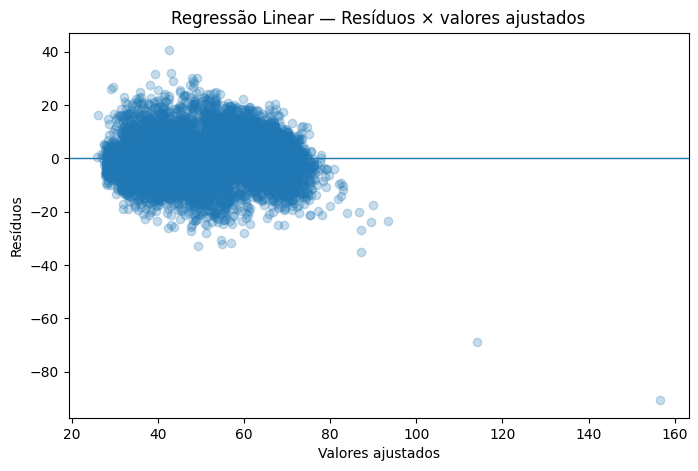

In [22]:
# Resíduos × valores ajustados
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(ajustados, residuos, alpha=0.25)
plt.axhline(0, linewidth=1)
plt.xlabel("Valores ajustados")
plt.ylabel("Resíduos")
plt.title("Regressão Linear — Resíduos × valores ajustados")
plt.show()


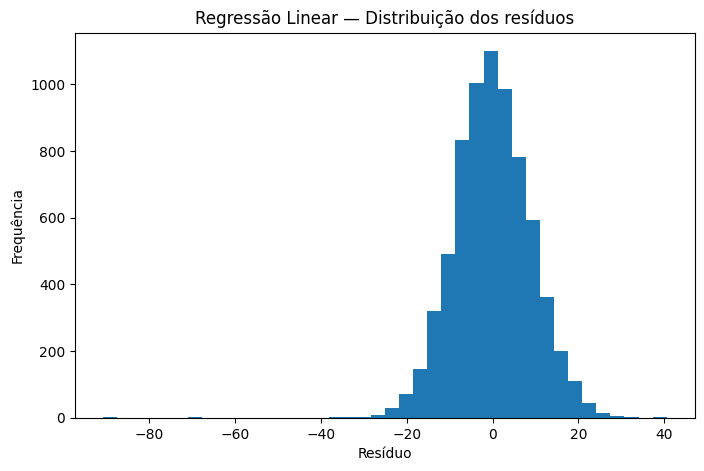

In [23]:
# Distribuição dos resíduos
plt.figure(figsize=(8, 5))
plt.hist(residuos, bins=40)
plt.xlabel("Resíduo")
plt.ylabel("Frequência")
plt.title("Regressão Linear — Distribuição dos resíduos")
plt.show()


In [24]:
# VIF
vif_resultados = []

for i, coluna in enumerate(X_diag_const.columns):
    if coluna == "const":
        continue

    vif_resultados.append({
        "variavel": coluna,
        "VIF": variance_inflation_factor(X_diag_const.values, i)
    })

vif_resultados = (
    pd.DataFrame(vif_resultados)
    .sort_values("VIF", ascending=False)
)

display(vif_resultados.round(3))


,variavel,VIF
3,active_days,13.954
0,usage_events,12.480
1,requests_total,8.447
6,distinct_applications,7.711
5,distinct_tools,6.853
4,requests_per_active_day,5.189
12,tool_hhi,4.179
2,total_tokens,2.718
9,failure_rate,1.530
8,latency_missing_rate,1.528


In [25]:
# Teste de Breusch-Pagan para heterocedasticidade
bp_lm, bp_lm_pvalue, bp_f, bp_f_pvalue = het_breuschpagan(
    residuos,
    X_diag_const
)

print("Breusch-Pagan")
print("LM:", round(bp_lm, 4))
print("p-valor LM:", bp_lm_pvalue)
print("F:", round(bp_f, 4))
print("p-valor F:", bp_f_pvalue)

if bp_lm_pvalue < 0.05:
    print("\nHá evidência de heterocedasticidade (p < 0,05).")
else:
    print("\nNão há evidência suficiente de heterocedasticidade (p >= 0,05).")


Breusch-Pagan
LM: 1777.6998
p-valor LM: 0.0
F: 181.959
p-valor F: 0.0

Há evidência de heterocedasticidade (p < 0,05).


Limite de referência 4/n: 0.0005624296962879641
Observações acima do limite: 243


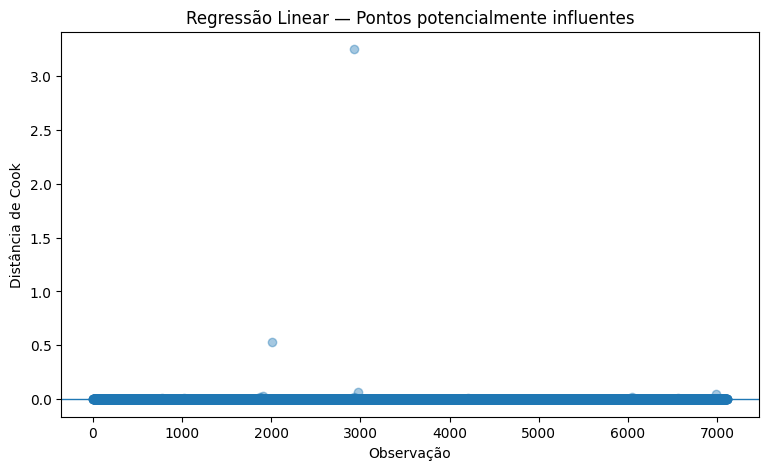

In [26]:
# Pontos influentes — distância de Cook
influencia = ols.get_influence()
cook = influencia.cooks_distance[0]

limite_cook = 4 / len(treino)
qtd_influentes = int((cook > limite_cook).sum())

print("Limite de referência 4/n:", limite_cook)
print("Observações acima do limite:", qtd_influentes)

plt.figure(figsize=(9, 5))
plt.scatter(np.arange(len(cook)), cook, alpha=0.4)
plt.axhline(limite_cook, linewidth=1)
plt.xlabel("Observação")
plt.ylabel("Distância de Cook")
plt.title("Regressão Linear — Pontos potencialmente influentes")
plt.show()


## 3. Resultados das previsões

Depois de escolher o modelo somente com o treino e a validação cruzada, ele é ajustado com **todo o conjunto de treino** e avaliado uma única vez no conjunto de teste reservado.


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_test = teste[FEATURES]
y_test = teste[ALVO]

# Modelo selecionado pela validação cruzada.
melhor_modelo.fit(X_train, y_train)
pred_teste = melhor_modelo.predict(X_test)

# Baseline ajustado exclusivamente no treino.
baseline_final = modelos["Baseline (média)"]
baseline_final.fit(X_train, y_train)
pred_baseline_teste = baseline_final.predict(X_test)

mae_teste = mean_absolute_error(y_test, pred_teste)
rmse_teste = np.sqrt(mean_squared_error(y_test, pred_teste))
r2_teste = r2_score(y_test, pred_teste)

mae_base_teste = mean_absolute_error(y_test, pred_baseline_teste)
rmse_base_teste = np.sqrt(mean_squared_error(y_test, pred_baseline_teste))
r2_base_teste = r2_score(y_test, pred_baseline_teste)

print("Modelo final:", melhor_nome)
print(f"MAE teste: {mae_teste:.2f} pontos")
print(f"RMSE teste: {rmse_teste:.2f} pontos")
print(f"R² teste: {r2_teste:.4f}")

print("\nBaseline:")
print(f"MAE baseline: {mae_base_teste:.2f} pontos")
print(f"RMSE baseline: {rmse_base_teste:.2f} pontos")
print(f"R² baseline: {r2_base_teste:.4f}")


Modelo final: Random Forest
MAE teste: 5.92 pontos
RMSE teste: 7.54 pontos
R² teste: 0.7893

Baseline:
MAE baseline: 14.19 pontos
RMSE baseline: 16.44 pontos
R² baseline: -0.0012


### 3.1 Previsões individuais do conjunto de teste

A tabela abaixo mostra casos em que o resultado real já é conhecido. Isso permite comparar diretamente a previsão com o valor observado.


In [28]:
previsoes_teste = teste[
    ["employee_id", "year_month", ALVO]
].copy()

previsoes_teste["risk_score_previsto"] = pred_teste
previsoes_teste["erro"] = (
    previsoes_teste[ALVO] -
    previsoes_teste["risk_score_previsto"]
)
previsoes_teste["erro_absoluto"] = previsoes_teste["erro"].abs()

display(
    previsoes_teste[
        [
            "employee_id",
            "year_month",
            ALVO,
            "risk_score_previsto",
            "erro_absoluto"
        ]
    ]
    .head(20)
    .round(2)
)


,employee_id,year_month,risk_score_next_month,risk_score_previsto,erro_absoluto
7112,C01-E0001,2026-03,37.56,31.68,5.88
7113,C01-E0003,2026-03,29.29,37.47,8.18
7114,C01-E0004,2026-03,62.52,65.45,2.92
7115,C01-E0005,2026-03,62.59,72.20,9.62
7116,C01-E0006,2026-03,45.44,43.55,1.89
7117,C01-E0007,2026-03,71.69,71.37,0.32
7118,C01-E0009,2026-03,72.33,69.76,2.57
7119,C01-E0010,2026-03,21.72,28.22,6.50
7120,C01-E0011,2026-03,56.10,61.16,5.05
7121,C01-E0012,2026-03,40.94,39.46,1.48


### 3.2 Valores reais × previstos


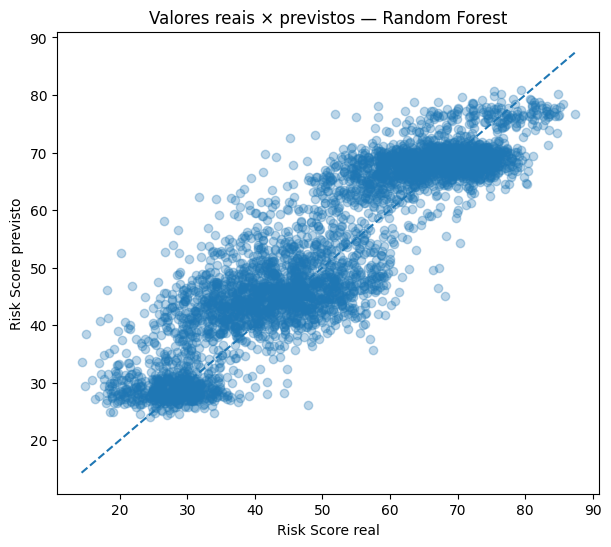

In [29]:
plt.figure(figsize=(7, 6))
plt.scatter(
    y_test,
    pred_teste,
    alpha=0.30
)

lim_min = min(y_test.min(), pred_teste.min())
lim_max = max(y_test.max(), pred_teste.max())

plt.plot(
    [lim_min, lim_max],
    [lim_min, lim_max],
    linestyle="--"
)

plt.xlabel("Risk Score real")
plt.ylabel("Risk Score previsto")
plt.title(f"Valores reais × previstos — {melhor_nome}")
plt.show()


### 3.3 Onde o modelo apresenta maiores erros

Para não criar faixas arbitrárias de risco, dividimos o valor real do teste em **quartis** e calculamos o MAE dentro de cada grupo. Também avaliamos o erro por mês.


In [30]:
# Erro por quartil do valor real
previsoes_teste["quartil_real"] = pd.qcut(
    previsoes_teste[ALVO],
    q=4,
    duplicates="drop"
)

erro_por_quartil = (
    previsoes_teste
    .groupby("quartil_real", observed=True)
    .agg(
        observacoes=("employee_id", "count"),
        MAE=("erro_absoluto", "mean")
    )
    .reset_index()
)

display(erro_por_quartil.round(3))


,quartil_real,observacoes,MAE
0,"(14.341000000000001, 36.66]",1015,6.945
1,"(36.66, 49.796]",1014,5.504
2,"(49.796, 64.991]",1013,7.148
3,"(64.991, 87.343]",1014,4.084


In [31]:
# Erro por mês de referência
erro_por_mes = (
    previsoes_teste
    .groupby("year_month")
    .agg(
        observacoes=("employee_id", "count"),
        MAE=("erro_absoluto", "mean")
    )
    .reset_index()
)

display(erro_por_mes.round(3))


,year_month,observacoes,MAE
0,2026-03,999,5.752
1,2026-04,1010,5.884
2,2026-05,1021,5.910
3,2026-06,1026,6.130


In [32]:
# Casos com maiores erros absolutos
display(
    previsoes_teste
    .sort_values("erro_absoluto", ascending=False)
    .head(10)
    [
        [
            "employee_id",
            "year_month",
            ALVO,
            "risk_score_previsto",
            "erro_absoluto"
        ]
    ]
    .round(2)
)


,employee_id,year_month,risk_score_next_month,risk_score_previsto,erro_absoluto
10392,C01-E0328,2026-06,20.13,52.51,32.38
7316,C01-E0268,2026-03,26.55,58.10,31.56
8353,C01-E0321,2026-04,31.72,62.25,30.53
8810,C10-E0055,2026-04,41.55,69.68,28.12
8730,C07-E0070,2026-04,18.08,46.18,28.10
7493,C03-E0023,2026-03,28.68,56.46,27.78
7611,C06-E0079,2026-03,34.28,61.92,27.64
9715,C06-E0325,2026-05,45.24,72.53,27.30
10271,C01-E0172,2026-06,39.37,65.51,26.14
7654,C06-E0235,2026-03,43.15,69.29,26.14


## 4. Métricas e evidências da validação

### 4.1 Evidências da validação cruzada

A tabela de validação cruzada apresenta, para cada modelo:

- **MAE médio e desvio-padrão**;
- **RMSE médio e desvio-padrão**;
- **R² médio e desvio-padrão**.

MAE e RMSE permanecem na escala original do Risk Score, de 0 a 100.


In [33]:
display(
    resultados_cv[
        [
            "modelo",
            "MAE_medio",
            "MAE_desvio",
            "RMSE_medio",
            "RMSE_desvio",
            "R2_medio",
            "R2_desvio"
        ]
    ].round(3)
)


,modelo,MAE_medio,MAE_desvio,RMSE_medio,RMSE_desvio,R2_medio,R2_desvio
0,Random Forest,6.161,0.352,7.841,0.460,0.753,0.040
1,HistGradientBoosting,6.181,0.421,7.859,0.522,0.751,0.044
2,Regressão Linear,7.211,0.528,9.123,0.597,0.665,0.056
3,Ridge,7.213,0.529,9.123,0.598,0.665,0.056
4,Baseline (média),13.670,0.335,15.867,0.372,-0.001,0.001


### 4.2 Comparação final com a referência simples


In [34]:
melhoria_mae = (
    (mae_base_teste - mae_teste) /
    mae_base_teste * 100
)

comparacao_teste = pd.DataFrame([
    {
        "modelo": "Baseline (média)",
        "MAE": mae_base_teste,
        "RMSE": rmse_base_teste,
        "R2": r2_base_teste
    },
    {
        "modelo": melhor_nome,
        "MAE": mae_teste,
        "RMSE": rmse_teste,
        "R2": r2_teste
    }
])

display(comparacao_teste.round(3))

print(
    f"Redução do MAE em relação ao baseline: "
    f"{melhoria_mae:.2f}%"
)


,modelo,MAE,RMSE,R2
0,Baseline (média),14.19,16.438,-0.001
1,Random Forest,5.92,7.541,0.789


Redução do MAE em relação ao baseline: 58.28%


### 4.3 Conclusão da validação

A conclusão deve ser baseada nos resultados produzidos pelas células anteriores:

1. **O modelo supera a referência simples?**  
   Sim, somente se o MAE do modelo final for menor que o MAE do baseline no teste reservado.

2. **O erro é aceitável para a decisão pretendida?**  
   O MAE mostra diretamente quantos pontos do Risk Score o modelo erra em média.Podemos demonstrar desempenho e ganho em relação ao baseline, mas a aceitação operacional do erro ainda precisa ser validada com o stakeholder.

3. **Em quais situações o modelo funciona pior?**  
   Isso é demonstrado pelas tabelas de erro por quartil, erro por mês e pelos casos com maior erro absoluto.

4. **R² ou significância isoladamente são suficientes?**  
   Não. A decisão sobre o modelo é baseada principalmente em desempenho fora da amostra, utilizando validação temporal e conjunto de teste reservado. Os diagnósticos da regressão linear são evidências complementares.

5. **Limitação central:**  
   O alvo é um Risk Score operacional construído pelo projeto a partir dos dados disponíveis. O modelo prevê esse indicador, e não uma medida externa e independente de dependência. A validade do score como indicador de negócio deve continuar sendo avaliada separadamente.


In [35]:
# Resumo automático para facilitar a redação do relatório
print("RESUMO FINAL")
print("-" * 60)
print("Modelo escolhido:", melhor_nome)
print(f"MAE CV: {resultados_cv.loc[0, 'MAE_medio']:.2f} ± {resultados_cv.loc[0, 'MAE_desvio']:.2f}")
print(f"RMSE CV: {resultados_cv.loc[0, 'RMSE_medio']:.2f} ± {resultados_cv.loc[0, 'RMSE_desvio']:.2f}")
print(f"R² CV: {resultados_cv.loc[0, 'R2_medio']:.3f} ± {resultados_cv.loc[0, 'R2_desvio']:.3f}")
print()
print(f"MAE no teste: {mae_teste:.2f}")
print(f"RMSE no teste: {rmse_teste:.2f}")
print(f"R² no teste: {r2_teste:.3f}")
print()
print(f"MAE baseline no teste: {mae_base_teste:.2f}")
print(f"Redução de MAE vs. baseline: {melhoria_mae:.2f}%")


RESUMO FINAL
------------------------------------------------------------
Modelo escolhido: Random Forest
MAE CV: 6.16 ± 0.35
RMSE CV: 7.84 ± 0.46
R² CV: 0.753 ± 0.040

MAE no teste: 5.92
RMSE no teste: 7.54
R² no teste: 0.789

MAE baseline no teste: 14.19
Redução de MAE vs. baseline: 58.28%
